# 1a — Network Figures

## Purpose
Produce reference visualisations of the Costa Rican official road network and the OpenStreetMap (OSM) road network to verify data coverage and quality before analysis.

## Inputs
| File | Description |
|------|-------------|
| `input_files/CR_RED_TOPOGRAFICA/cr_red_topografica.shp` | Modified cantonal road network; attribute `CLASE` (Primaria / Secundaria / Terciaria / Local) used for road class |
| `input_files/CR_RVN_TOPOGRAFICA_V3/cr_rvn_topografica_v3.shp` | National road network (same `CLASE` attribute) |
| `input_files/costa-rica-260713.osm.pbf` | OpenStreetMap road data for Costa Rica |
| `input_files/ids_2023_distrital/ids_2023_distrito.shp` | District polygons, dissolved into the national boundary used to clip and frame the maps (via `src/map_style_cr.py`) |
| `input_files/CENTROS_POBLACION/centros_poblados_localidades.shp` | Liberia and Limón city points for the map labels (via `src/map_style_cr.py`) |

## Outputs
| File | Description |
|------|-------------|
| `figures/osm_road_network.png` | OSM road network map coloured by category |
| `figures/road_categories_national.png` | National network map coloured by road class |
| `figures/road_categories_modified_contonal.png` | Modified cantonal network map coloured by road class |
| `figures/road_network_comparison.png` | Three-panel comparison of cantonal / national / OSM networks |
| `figures/road_length_by_category.png` | Bar chart of total network length per dataset |
| `figures/aadt_completeness_by_network.png`, `.csv` | AADT attribute completeness per network |
| `figures/missing_aadt_modified_cantonal.png` | Map of cantonal segments missing at least one AADT category |

## Key Processing Steps
1. **Load OSM data** — read `.pbf` file, extract `highway` tags from the `other_tags` field
2. **Crop to the country** — clip the OSM network to the mainland national boundary (IDS districts dissolved; far-offshore parts such as Isla del Coco are dropped). The raw OSM extract is a bounding box that spills into Nicaragua and Panama, so without this the OSM maps are not comparable with the official-network maps.
3. **Categorise roads** — map OSM highway types to six groups (motorway, trunk, primary, secondary, tertiary, other) aligned with the Costa Rican hierarchy (motorway / trunk / primary → Primaria, secondary → Secundaria, tertiary → Terciaria, other → Local)
4. **Plot individual networks** — official networks coloured by `CLASE`; OSM network coloured by mapped category. Every map is finished with `style_cr_map` (`src/map_style_cr.py`): mainland extent, CARTO Positron basemap, area outside Costa Rica faded, national outline, San José / Liberia / Limón, legend upper right
5. **Side-by-side comparison** — three-panel figure sharing one extent for direct visual comparison
6. **Length statistics** — compute total road length per dataset in CRTM05 (EPSG:8908), the metric national projection (log scale when max/min ratio > 100); OSM is counted inside Costa Rica only
7. **AADT completeness** — tabulate and map missing AADT (`T9`–`T15`) attributes

In [1]:
# Standard library
import os
import re
import sys
import warnings
from pathlib import Path

# Third-party - Data and scientific computing
import geopandas as gpd
import numpy as np
import pandas as pd
from tqdm import tqdm

# Shapely-specific imports for spatial analysis
import shapely
from shapely import STRtree
from shapely.geometry import LineString, MultiLineString, Point
from shapely.ops import nearest_points, snap

# Matplotlib-specific imports for figures
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter, MultipleLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Suppress warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=RuntimeWarning)

In [2]:
BASE_DIR = Path.cwd().parent   # if notebook is in /notebooks
data_path = BASE_DIR / "input_files"
figure_path = BASE_DIR / "figures"

# Shared CR map style: extent, basemap, outline, cities, legend (src/map_style_cr.py)
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))
from src.map_style_cr import get_cr_boundary, style_cr_map

#create figures folder if it doesn't exist already
os.makedirs(figure_path, exist_ok=True)

osm_path = data_path / "costa-rica-260713.osm.pbf"
modified_cantonal_roads_path = data_path / "CR_RED_TOPOGRAFICA" / "cr_red_topografica.shp"
national_roads_path = data_path / "CR_RVN_TOPOGRAFICA_V3" / "cr_rvn_topografica_v3.shp"

In [3]:
features = gpd.read_file(osm_path, layer="lines")
features = features[features["highway"].notnull()]
osm_keys = ['highway','name','maxspeed','oneway','lanes','surface']

In [4]:
def _extract_value(text, key):
    """
    Parse the value of a specific key from a semi-structured OSM tag string.

    Args:
        text (str): Raw OSM `other_tags` string.
        key (str): Key to extract value for.

    Returns:
        str or None: Extracted value or None.
    """
    pattern = rf'"{key}"=>"([^"]+)"'
    try:
        match = re.search(pattern, text)
        if match:
            return match.group(1)
        return None
    except Exception:
        return None

In [5]:
road_types = ['primary','trunk','motorway','motorway_link','trunk_link','primary_link','secondary','secondary_link','tertiary','tertiary_link','residential','road','unclassified','track']

for key in osm_keys:
    if key not in features.columns:
        features[key] = features["other_tags"].apply(
            lambda x: _extract_value(x, key)
        )

base_network = features[features['highway'].isin(road_types)].reset_index(drop=True)
base_network = base_network[['osm_id','highway','name','maxspeed','oneway','lanes','surface','geometry']] #,'bridge','tunnel'    


In [ ]:
# ---------------------------------------------------------------------------
# Clip OSM to the country
# ---------------------------------------------------------------------------
# The OSM file is a bounding-box extract: it spills into Nicaragua and Panama
# and reaches Isla del Coco (~500 km offshore), so the OSM maps came out far
# wider than the official-network maps. The OSM network is therefore clipped to
# the national boundary. Every map is framed on mainland Costa Rica by
# style_cr_map.
#
# Assumptions (figure framing only — no analysis input is modified):
#   * Boundary = MIDEPLAN IDS 2023 district polygons, dissolved, mainland only
#     (Isla del Coco dropped) — see src/map_style_cr.py.
#   * CLIP_BUFFER_M tolerance so coastal and border roads are not shaved off by
#     small differences between the road and boundary geometries.

CLIP_BUFFER_M = 1_000          # clip tolerance around the national boundary

cr_boundary = get_cr_boundary(8908)

# --- clip the OSM network to the national boundary ---
osm_length_before_km = base_network.to_crs(8908).length.sum() / 1000
base_network_cr = gpd.clip(base_network.to_crs(8908), cr_boundary.buffer(CLIP_BUFFER_M))
base_network_cr = (
    base_network_cr[~base_network_cr.geometry.is_empty & base_network_cr.geometry.notna()]
    .reset_index(drop=True)
)
print(
    f"OSM segments: {len(base_network):,} -> {len(base_network_cr):,} after clipping to Costa Rica"
)
print(
    f"OSM length:   {osm_length_before_km:,.0f} km -> "
    f"{base_network_cr.length.sum() / 1000:,.0f} km"
)

gdf_modified_cantonal = gpd.read_file(modified_cantonal_roads_path)
gdf_modified_cantonal["CLASE"] = gdf_modified_cantonal["CLASE"].fillna("Sin clasificar")

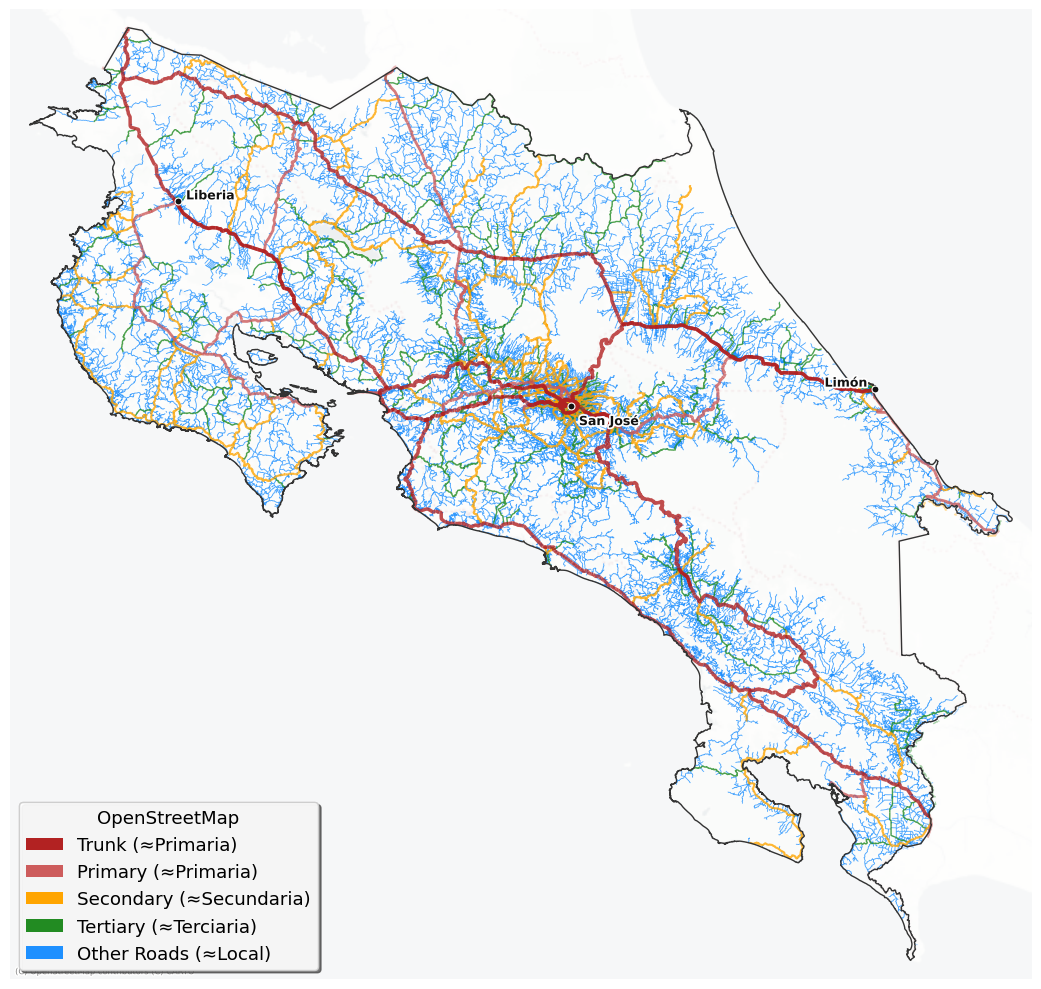

In [ ]:
# Define the road types to include
road_types = ['primary','trunk','motorway','motorway_link','trunk_link','primary_link','secondary','secondary_link','tertiary','tertiary_link','residential','road','unclassified']

# Filter for the road types we want to plot.
# base_network_cr is the OSM network clipped to the national boundary, so this
# map shows Costa Rican roads only.
base_network_filtered = base_network_cr[base_network_cr['highway'].isin(road_types)].copy()

# Create a mapping to group _link roads with their parent categories
def map_road_category(highway_type):
    if highway_type in ['motorway', 'motorway_link']:
        return 'motorway'
    elif highway_type in ['trunk', 'trunk_link']:
        return 'trunk'
    elif highway_type in ['primary', 'primary_link']:
        return 'primary'
    elif highway_type in ['secondary', 'secondary_link']:
        return 'secondary'
    elif highway_type in ['tertiary', 'tertiary_link']:
        return 'tertiary'
    elif highway_type in ['residential', 'road', 'unclassified', 'track']:
        return 'other'
    else:
        return highway_type
        
# Apply the mapping
base_network_filtered['road_category'] = base_network_filtered['highway'].apply(map_road_category)

# Define colors matching the Costa Rican road network hierarchy
# Motorway/Trunk/Primary ≈ Primaria (reds), Secondary ≈ Secundaria (orange),
# Tertiary ≈ Terciaria (green), Other ≈ Local (blue)
road_colors = {
    'motorway': '#8B0000',    # Dark red/maroon (like Costa Rican Primaria)
    'trunk': '#B22222',       # Firebrick red (like Costa Rican Primaria)
    'primary': '#CD5C5C',     # Indian red (like Costa Rican Primaria)
    'secondary': '#FFA500',   # Orange (like Costa Rican Secundaria)
    'tertiary': '#228B22',    # Green (like Costa Rican Terciaria)
    'other': '#1E90FF'        # Blue (residential, road, unclassified — like Costa Rican Local)
}

# Define line widths - hierarchical from motorway (thickest) to other (thinnest)
road_widths = {
    'motorway': 3.0,   # Highways - thickest
    'trunk': 2.5,      # Trunk roads
    'primary': 2.0,    # Primary roads
    'secondary': 1.5,  # Secondary roads
    'tertiary': 1,     # Tertiary roads
    'other': 0.6       # Other roads - thinnest
}

# Define the order for plotting and legend (highest to lowest hierarchy)
road_hierarchy = ['motorway', 'trunk', 'primary', 'secondary', 'tertiary', 'other']

# Create figure with high DPI for crisp visuals
fig, ax = plt.subplots(1, 1, figsize=(12, 10), facecolor='white')

# Convert to Web Mercator for plotting with basemap
network_mercator = base_network_filtered.to_crs(3857)

# Plot each road category with its specific color and width
# Plot in reverse hierarchy order so motorways appear on top
for category in reversed(road_hierarchy):
    if category in base_network_filtered['road_category'].values:
        category_roads = network_mercator[network_mercator['road_category'] == category]
        category_roads.plot(
            ax=ax,
            color=road_colors[category],
            linewidth=road_widths[category],
            alpha=0.8,
            zorder=road_widths[category]  # Higher tier roads on top
        )

road_labels = {
    'motorway': 'Motorway (≈Primaria)',
    'trunk': 'Trunk (≈Primaria)', 
    'primary': 'Primary (≈Primaria)',
    'secondary': 'Secondary (≈Secundaria)',
    'tertiary': 'Tertiary (≈Terciaria)',
    'other': 'Other Roads (≈Local)'
}
legend_elements = [
    Patch(facecolor=road_colors[category], label=road_labels[category], edgecolor='none')
    for category in road_hierarchy
    if category in base_network_filtered['road_category'].values
]

# Shared CR style: extent, basemap, outside fade, outline, cities, legend
style_cr_map(ax, 3857, legend_handles=legend_elements, legend_title='OpenStreetMap')

plt.tight_layout()
plt.savefig(figure_path / 'osm_road_network.png', dpi=300, bbox_inches='tight')
plt.show()

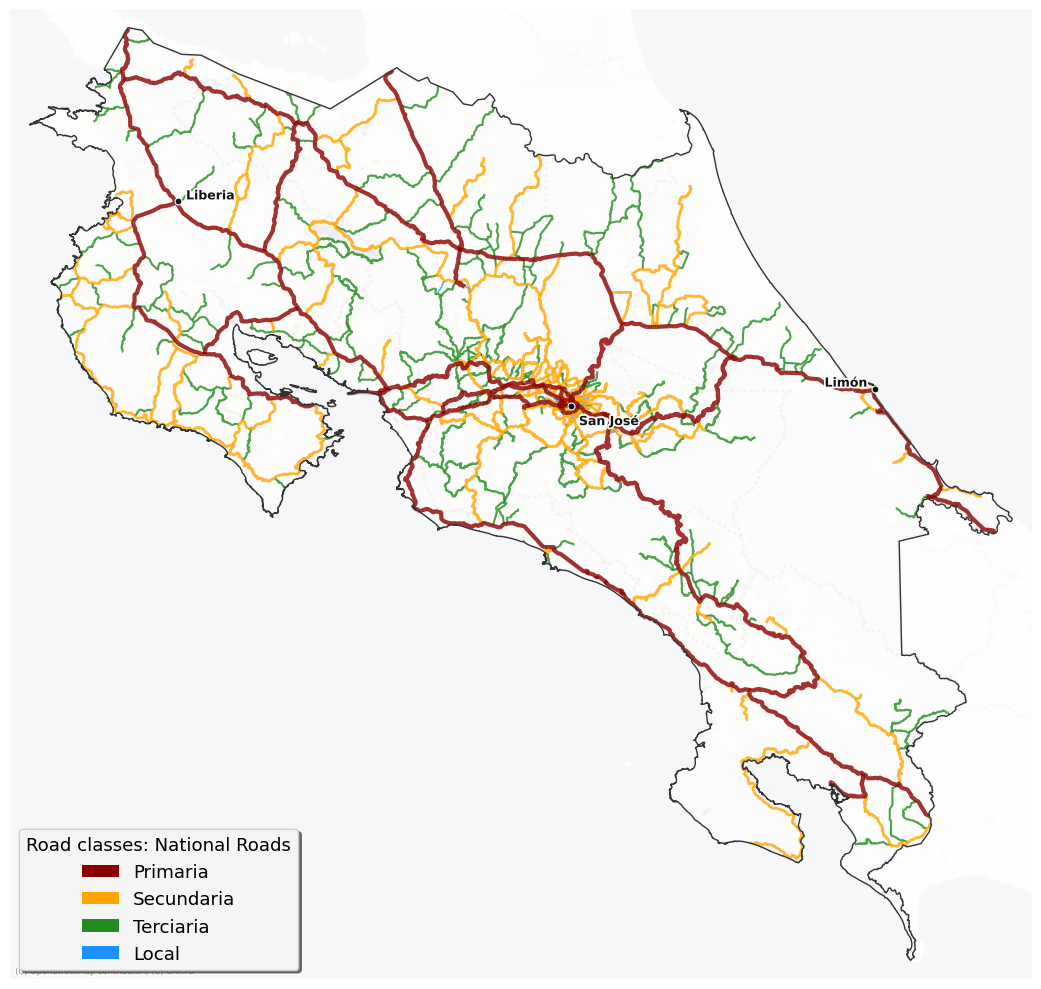

In [ ]:
gdf_national = gpd.read_file(national_roads_path)

# Label unclassified segments explicitly so they can be styled and reported
gdf_national["CLASE"] = gdf_national["CLASE"].fillna("Sin clasificar")

# Road classes to plot (highest to lowest hierarchy)
road_categories = ['Primaria', 'Secundaria', 'Terciaria', 'Local', 'Sin clasificar']
gdf_filtered = gdf_national[gdf_national['CLASE'].isin(road_categories)].copy()

# Define colors for the Costa Rican road classes
road_colors = {
    'Primaria': '#8B0000',        # Dark red/maroon
    'Secundaria': '#FFA500',      # Orange
    'Terciaria': '#228B22',       # Green
    'Local': '#1E90FF',           # Blue
    'Sin clasificar': '#999999',  # Grey
}

# Define line widths - higher tier roads are wider
road_widths = {
    'Primaria': 3.0,        # Primary national roads - thickest
    'Secundaria': 2.0,      # Secondary roads
    'Terciaria': 1.5,       # Tertiary roads
    'Local': 1.0,           # Local roads
    'Sin clasificar': 0.8,  # Unclassified - thinnest
}

# Create figure with high DPI for crisp visuals
fig, ax = plt.subplots(1, 1, figsize=(12, 10), facecolor='white')

# Convert to Web Mercator for plotting with basemap
gdf_mercator = gdf_filtered.to_crs(3857)

# Plot each road class with its specific color and width
for category in road_categories:
    if category in gdf_filtered['CLASE'].values:
        category_roads = gdf_mercator[gdf_mercator['CLASE'] == category]
        category_roads.plot(
            ax=ax,
            color=road_colors[category],
            linewidth=road_widths[category],
            alpha=0.8,
            zorder=road_widths[category]  # Higher tier roads on top
        )

legend_elements = [
    Patch(facecolor=road_colors[category], label=category, edgecolor='none')
    for category in road_categories if category in gdf_filtered['CLASE'].values
]
style_cr_map(ax, 3857, legend_handles=legend_elements, legend_title='Road classes: National Roads')

plt.tight_layout()
plt.savefig(figure_path / 'road_categories_national.png', dpi=300, bbox_inches='tight')
plt.show()

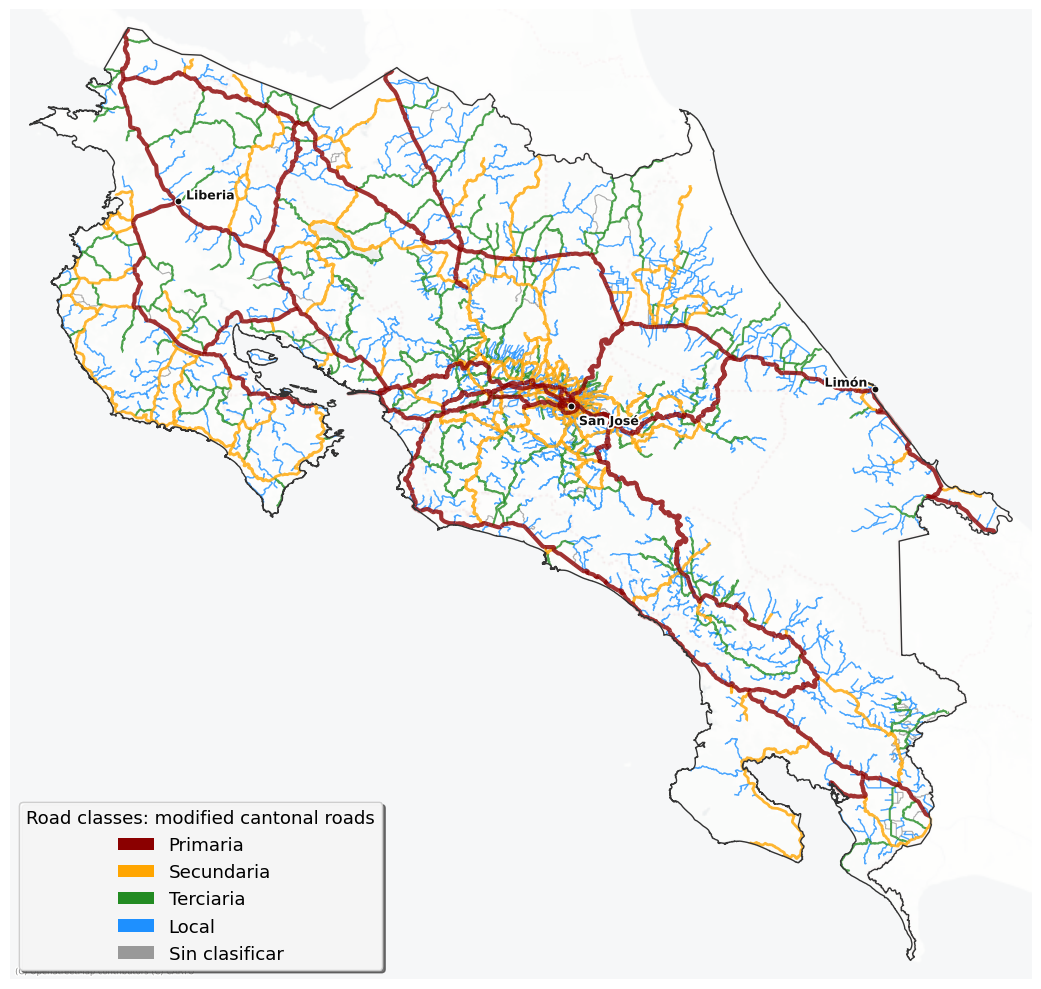

In [ ]:
gdf_modified_cantonal = gpd.read_file(modified_cantonal_roads_path)

# Label unclassified segments explicitly so they can be styled and reported
gdf_modified_cantonal["CLASE"] = gdf_modified_cantonal["CLASE"].fillna("Sin clasificar")

# Road classes to plot (highest to lowest hierarchy)
road_categories = ['Primaria', 'Secundaria', 'Terciaria', 'Local', 'Sin clasificar']
gdf_filtered = gdf_modified_cantonal[gdf_modified_cantonal['CLASE'].isin(road_categories)].copy()

# Define colors for the Costa Rican road classes
road_colors = {
    'Primaria': '#8B0000',        # Dark red/maroon
    'Secundaria': '#FFA500',      # Orange
    'Terciaria': '#228B22',       # Green
    'Local': '#1E90FF',           # Blue
    'Sin clasificar': '#999999',  # Grey
}

# Define line widths - higher tier roads are wider
road_widths = {
    'Primaria': 3.0,        # Primary national roads - thickest
    'Secundaria': 2.0,      # Secondary roads
    'Terciaria': 1.5,       # Tertiary roads
    'Local': 1.0,           # Local roads
    'Sin clasificar': 0.8,  # Unclassified - thinnest
}

# Create figure with high DPI for crisp visuals
fig, ax = plt.subplots(1, 1, figsize=(12, 10), facecolor='white')

# Convert to Web Mercator for plotting with basemap
gdf_mercator = gdf_filtered.to_crs(3857)

# Plot each road class with its specific color and width
for category in road_categories:
    if category in gdf_filtered['CLASE'].values:
        category_roads = gdf_mercator[gdf_mercator['CLASE'] == category]
        category_roads.plot(
            ax=ax,
            color=road_colors[category],
            linewidth=road_widths[category],
            alpha=0.8,
            zorder=road_widths[category]  # Higher tier roads on top
        )

legend_elements = [
    Patch(facecolor=road_colors[category], label=category, edgecolor='none')
    for category in road_categories if category in gdf_filtered['CLASE'].values
]
style_cr_map(ax, 3857, legend_handles=legend_elements,
             legend_title='Road classes: modified cantonal roads')

plt.tight_layout()
plt.savefig(figure_path / 'road_categories_modified_contonal.png', dpi=300, bbox_inches='tight')
plt.show()

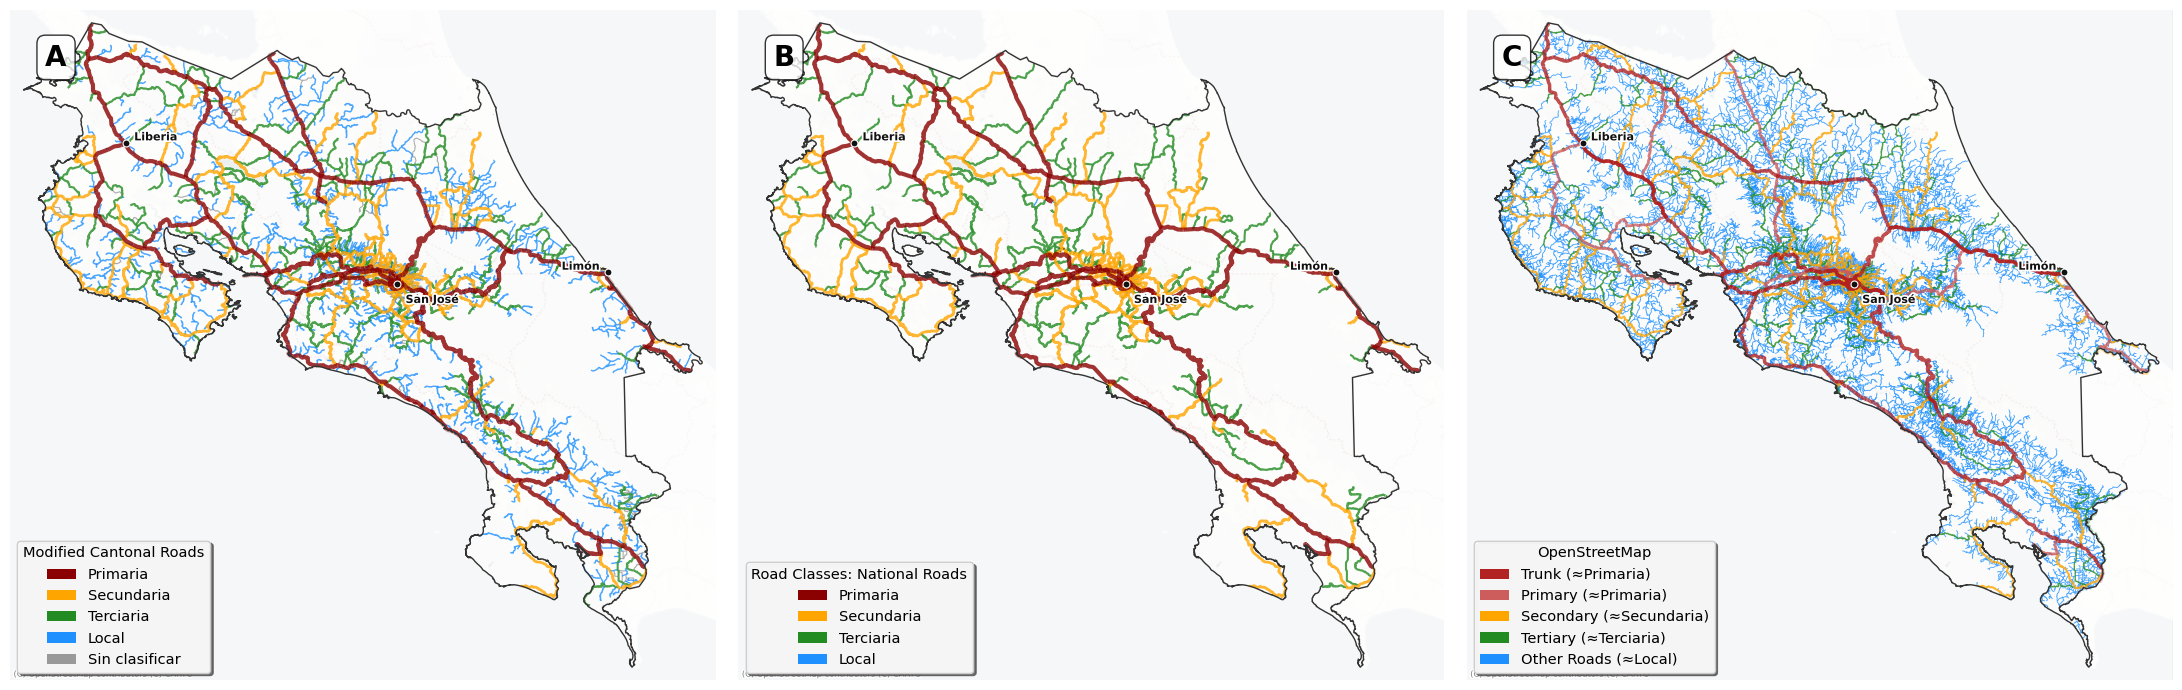

In [ ]:
# Create figure with three subplots
# All three panels share the mainland extent, and the OSM panel uses the
# boundary-clipped network, so the panels are directly comparable.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 7), facecolor='white')

road_categories = ['Primaria', 'Secundaria', 'Terciaria', 'Local', 'Sin clasificar']
road_colors_official = {
    'Primaria': '#8B0000', 'Secundaria': '#FFA500', 'Terciaria': '#228B22',
    'Local': '#1E90FF', 'Sin clasificar': '#999999'
}
road_widths_official = {
    'Primaria': 3.0, 'Secundaria': 2.0, 'Terciaria': 1.5, 'Local': 1.0, 'Sin clasificar': 0.8
}


def plot_official_network(axis, frame, title, panel_label):
    filtered = frame[frame['CLASE'].isin(road_categories)].copy()
    mercator = filtered.to_crs(3857)

    for category in road_categories:
        if category in filtered['CLASE'].values:
            category_roads = mercator[mercator['CLASE'] == category]
            category_roads.plot(
                ax=axis,
                color=road_colors_official[category],
                linewidth=road_widths_official[category],
                alpha=0.8,
                zorder=road_widths_official[category],
            )

    legend_elements = [
        Patch(facecolor=road_colors_official[cat], label=cat, edgecolor='none')
        for cat in road_categories if cat in filtered['CLASE'].values
    ]
    style_cr_map(axis, 3857, legend_handles=legend_elements, legend_title=title,
                 panel_label=panel_label, city_fontsize=8)


# ============ LEFT MAP (A) - Modified Cantonal Road Network ============
plot_official_network(ax1, gdf_modified_cantonal, 'Modified Cantonal Roads', 'A')

# ============ MIDDLE MAP (B) - National Road Network ============
plot_official_network(ax2, gdf_national, 'Road Classes: National Roads', 'B')

# ============ RIGHT MAP (C) - OSM Road Network (clipped to Costa Rica) ============
road_types = ['primary', 'trunk', 'motorway', 'motorway_link', 'trunk_link', 'primary_link',
              'secondary', 'secondary_link', 'tertiary', 'tertiary_link', 'residential',
              'road', 'unclassified']
base_network_filtered = base_network_cr[base_network_cr['highway'].isin(road_types)].copy()

def map_road_category(highway_type):
    if highway_type in ['motorway', 'motorway_link']:
        return 'motorway'
    elif highway_type in ['trunk', 'trunk_link']:
        return 'trunk'
    elif highway_type in ['primary', 'primary_link']:
        return 'primary'
    elif highway_type in ['secondary', 'secondary_link']:
        return 'secondary'
    elif highway_type in ['tertiary', 'tertiary_link']:
        return 'tertiary'
    elif highway_type in ['residential', 'road', 'unclassified', 'track']:
        return 'other'
    else:
        return highway_type

base_network_filtered['road_category'] = base_network_filtered['highway'].apply(map_road_category)
road_colors_osm = {
    'motorway': '#8B0000', 'trunk': '#B22222', 'primary': '#CD5C5C',
    'secondary': '#FFA500', 'tertiary': '#228B22', 'other': '#1E90FF'
}
road_widths_osm = {
    'motorway': 3.0, 'trunk': 2.5, 'primary': 2.0,
    'secondary': 1.5, 'tertiary': 1.0, 'other': 0.6
}
road_hierarchy = ['motorway', 'trunk', 'primary', 'secondary', 'tertiary', 'other']
road_labels = {
    'motorway': 'Motorway (≈Primaria)', 'trunk': 'Trunk (≈Primaria)', 'primary': 'Primary (≈Primaria)',
    'secondary': 'Secondary (≈Secundaria)', 'tertiary': 'Tertiary (≈Terciaria)', 'other': 'Other Roads (≈Local)'
}

network_mercator = base_network_filtered.to_crs(3857)

for category in reversed(road_hierarchy):
    if category in base_network_filtered['road_category'].values:
        category_roads = network_mercator[network_mercator['road_category'] == category]
        category_roads.plot(
            ax=ax3,
            color=road_colors_osm[category],
            linewidth=road_widths_osm[category],
            alpha=0.8,
            zorder=road_widths_osm[category],
        )

legend_elements3 = [
    Patch(facecolor=road_colors_osm[cat], label=road_labels[cat], edgecolor='none')
    for cat in road_hierarchy if cat in base_network_filtered['road_category'].values
]
style_cr_map(ax3, 3857, legend_handles=legend_elements3, legend_title='OpenStreetMap',
             panel_label='C', city_fontsize=8)

# Final adjustments
plt.tight_layout()
plt.savefig(figure_path / 'road_network_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

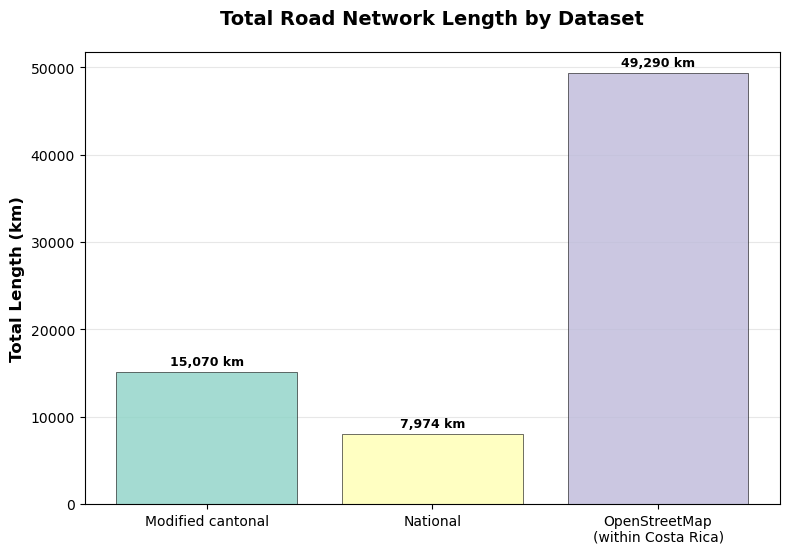

In [ ]:
# Convert each network to CRTM05 (EPSG:8908, metric) for accurate length calculation in km
# base_network_filtered comes from base_network_cr, i.e. OSM clipped to the
# national boundary, so all three totals cover the same territory.
modified_cantonal_crtm05 = gdf_modified_cantonal.to_crs(8908)
national_crtm05 = gdf_national.to_crs(8908)
osm_crtm05 = base_network_filtered.to_crs(8908)

# Calculate total length in kilometers for each network
modified_cantonal_length_km = modified_cantonal_crtm05.geometry.length.sum() / 1000
national_length_km = national_crtm05.geometry.length.sum() / 1000
osm_length_km = osm_crtm05.geometry.length.sum() / 1000

length_summary = pd.DataFrame({
    'network': ['Modified cantonal', 'National', 'OpenStreetMap\n(within Costa Rica)'],
    'length_km': [modified_cantonal_length_km, national_length_km, osm_length_km],
    'color': ['#8dd3c7', '#ffffb3', '#bebada']
})

# Create the bar plot
fig, ax = plt.subplots(1, 1, figsize=(8, 6), facecolor='white')

bars = ax.bar(
    length_summary['network'],
    length_summary['length_km'],
    color=length_summary['color'],
    alpha=0.8,
    edgecolor='black',
    linewidth=0.5,
)

# Use log scale only if the spread is very large
max_length = length_summary['length_km'].max()
min_length = length_summary['length_km'].min()
if min_length > 0 and max_length / min_length > 100:
    ax.set_yscale('log')
    ax.set_ylabel('Total Length (km) - Log Scale', fontsize=12, fontweight='bold')
    title_suffix = ' (Log Scale)'
else:
    ax.set_ylabel('Total Length (km)', fontsize=12, fontweight='bold')
    title_suffix = ''

# Add value labels on top of bars
for bar, length in zip(bars, length_summary['length_km']):
    height = bar.get_height()
    if ax.get_yscale() == 'log':
        text_y = height * 1.1
    else:
        text_y = height + max_length * 0.01

    if length >= 1000:
        label = f'{length:,.0f} km'
    else:
        label = f'{length:.1f} km'

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        text_y,
        label,
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
    )

ax.set_title(f'Total Road Network Length by Dataset{title_suffix}', fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, axis='y')
ax.set_axisbelow(True)

plt.tight_layout()
plt.subplots_adjust(bottom=0.15)
plt.savefig(figure_path / 'road_length_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# list column name for each dataset
print("Modified Cantonal Roads Columns:", gdf_modified_cantonal.columns.tolist())
print("National Roads Columns:", gdf_national.columns.tolist())


Modified Cantonal Roads Columns: ['ID_TRAMO', 'TRAMO_UID', 'ID_RUTA', 'NOMBRE', 'ADMIN', 'CLASE', 'LONGITUD', 'ANCHO', 'SUPERFICIE', 'REDUNDANCI', 'DIRECCION', 'CARRILES', 'T9', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15', 'vul_f', 'vul_eq', 'rep_cost_k', 'VEL_KMH', 'NODO_INI', 'NODO_FIN', 'COD_CAMI_1', 'Cod_camino', 'geometry']
National Roads Columns: ['TRAMO_UID', 'ID_TRAMO', 'ID_RUTA', 'NOMBRE', 'ADMIN', 'CLASE', 'LONGITUD', 'ANCHO', 'SUPERFICIE', 'REDUNDANCI', 'DIRECCION', 'CARRILES', 'T9', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15', 'vul_f', 'vul_eq', 'rep_cost_k', 'NODO_INI', 'NODO_FIN', 'geometry']


AADT completeness (% of segments with a non-null value)


network,Modified cantonal network,National network
aadt_category,,
Motorcycles,63.6,100.0
Pickup trucks,63.6,100.0
Passenger cars,63.6,100.0
Buses,63.6,100.0
Light trucks,63.5,100.0
Medium trucks,63.5,100.0
Heavy trucks,63.5,100.0


,network,aadt_code,aadt_category,complete_segments,total_segments,missing_segments,completeness_pct
0,Modified cantonal network,T9,Motorcycles,3030,4764,1734,63.6
1,Modified cantonal network,T10,Pickup trucks,3030,4764,1734,63.6
2,Modified cantonal network,T11,Passenger cars,3030,4764,1734,63.6
3,Modified cantonal network,T12,Buses,3028,4764,1736,63.6
4,Modified cantonal network,T13,Light trucks,3027,4764,1737,63.5
5,Modified cantonal network,T14,Medium trucks,3023,4764,1741,63.5
6,Modified cantonal network,T15,Heavy trucks,3027,4764,1737,63.5
7,National network,T9,Motorcycles,1453,1453,0,100.0
8,National network,T10,Pickup trucks,1453,1453,0,100.0
9,National network,T11,Passenger cars,1453,1453,0,100.0


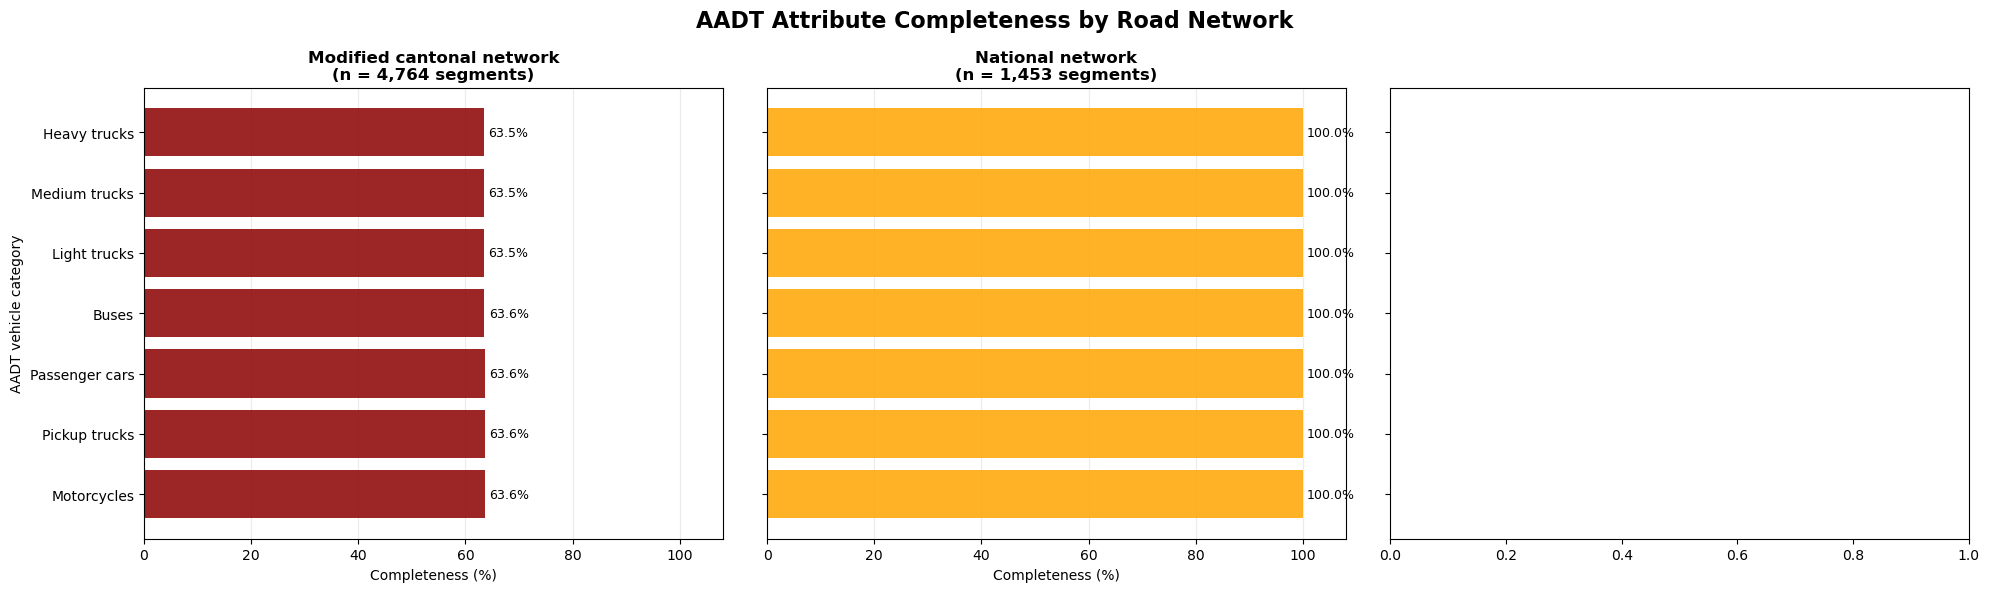

In [ ]:
# AADT: Average Annual Daily Traffic in 'T9', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15'
aadt_vehiculs_cat = ['T9', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15']
aadt_code_mapping = {'T9': 'Tráfico promedio diario anual de autos tipo motocicletas',
                     'T10': 'Tráfico promedio diario anual de autos tipo pickup',
                     'T11': 'Tráfico promedio diario anual de autos tipo normal',
                     'T12': 'Tráfico promedio diario anual de autobuses',
                     'T13': 'Tráfico promedio diario anual de camiones ligeros',
                     'T14': 'Tráfico promedio diario anual de camiones medianos',
                     'T15': 'Tráfico promedio diario anual de camiones pesados'
                     }

# AADT completeness EDA
# Zero is a reported traffic count; only NaN is treated as missing.
aadt_short_labels = {
    'T9': 'Motorcycles', 'T10': 'Pickup trucks', 'T11': 'Passenger cars',
    'T12': 'Buses', 'T13': 'Light trucks', 'T14': 'Medium trucks',
    'T15': 'Heavy trucks',
}

missing_aadt_columns = [c for c in aadt_vehiculs_cat
                        if c not in gdf_modified_cantonal.columns or c not in gdf_national.columns]
if missing_aadt_columns:
    raise KeyError(f'Missing expected AADT columns: {missing_aadt_columns}')

# The combined network has no dedicated cantonal flag. Use its Local road class
# as a reproducible proxy; update this mask if an authoritative flag is supplied.
# gdf_cantonal = gdf_modified_cantonal.loc[gdf_modified_cantonal['CLASE'].eq('Local')].copy()
aadt_networks = {
    'Modified cantonal network': gdf_modified_cantonal,
    #'Cantonal roads (Local class)': gdf_cantonal,
    'National network': gdf_national,
}

def aadt_completeness(frame, network_name):
    total = len(frame)
    complete = frame[aadt_vehiculs_cat].notna().sum()
    result = pd.DataFrame({
        'network': network_name,
        'aadt_code': aadt_vehiculs_cat,
        'aadt_category': [aadt_short_labels[c] for c in aadt_vehiculs_cat],
        'complete_segments': complete.reindex(aadt_vehiculs_cat).to_numpy(),
        'total_segments': total,
    })
    result['missing_segments'] = result['total_segments'] - result['complete_segments']
    result['completeness_pct'] = np.where(
        total > 0, 100 * result['complete_segments'] / total, np.nan
    )
    return result

aadt_completeness_long = pd.concat(
    [aadt_completeness(frame, name) for name, frame in aadt_networks.items()],
    ignore_index=True,
)
aadt_completeness_table = aadt_completeness_long.pivot(
    index='aadt_category', columns='network', values='completeness_pct'
).reindex(aadt_short_labels.values())

print('AADT completeness (% of segments with a non-null value)')
display(aadt_completeness_table.round(1))
display(aadt_completeness_long.round({'completeness_pct': 1}))
aadt_completeness_long.to_csv(figure_path / 'aadt_completeness_by_network.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True, facecolor='white')
plot_colors = ['#8B0000', '#FFA500', '#FFA500']
for ax, (network_name, _), color in zip(axes, aadt_networks.items(), plot_colors):
    subset = aadt_completeness_long[aadt_completeness_long['network'] == network_name]
    bars = ax.barh(subset['aadt_category'], subset['completeness_pct'], color=color, alpha=0.85)
    ax.bar_label(bars, labels=[f'{v:.1f}%' for v in subset['completeness_pct']], padding=3, fontsize=9)
    ax.set_xlim(0, 108)
    ax.set_xlabel('Completeness (%)')
    n_segments = int(subset['total_segments'].iloc[0])
    ax.set_title(f'{network_name}\n(n = {n_segments:,} segments)', fontweight='bold')
    ax.grid(axis='x', alpha=0.25)
    ax.set_axisbelow(True)
    ax.invert_yaxis()

axes[0].set_ylabel('AADT vehicle category')
fig.suptitle('AADT Attribute Completeness by Road Network', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(figure_path / 'aadt_completeness_by_network.png', dpi=300, bbox_inches='tight')
plt.show()


Segments missing at least one AADT category: 1,748 of 4,764 (36.7%)
Missing segments by road class:


,segments
CLASE,
Local,1620
Sin clasificar,119
Terciaria,5
Secundaria,4


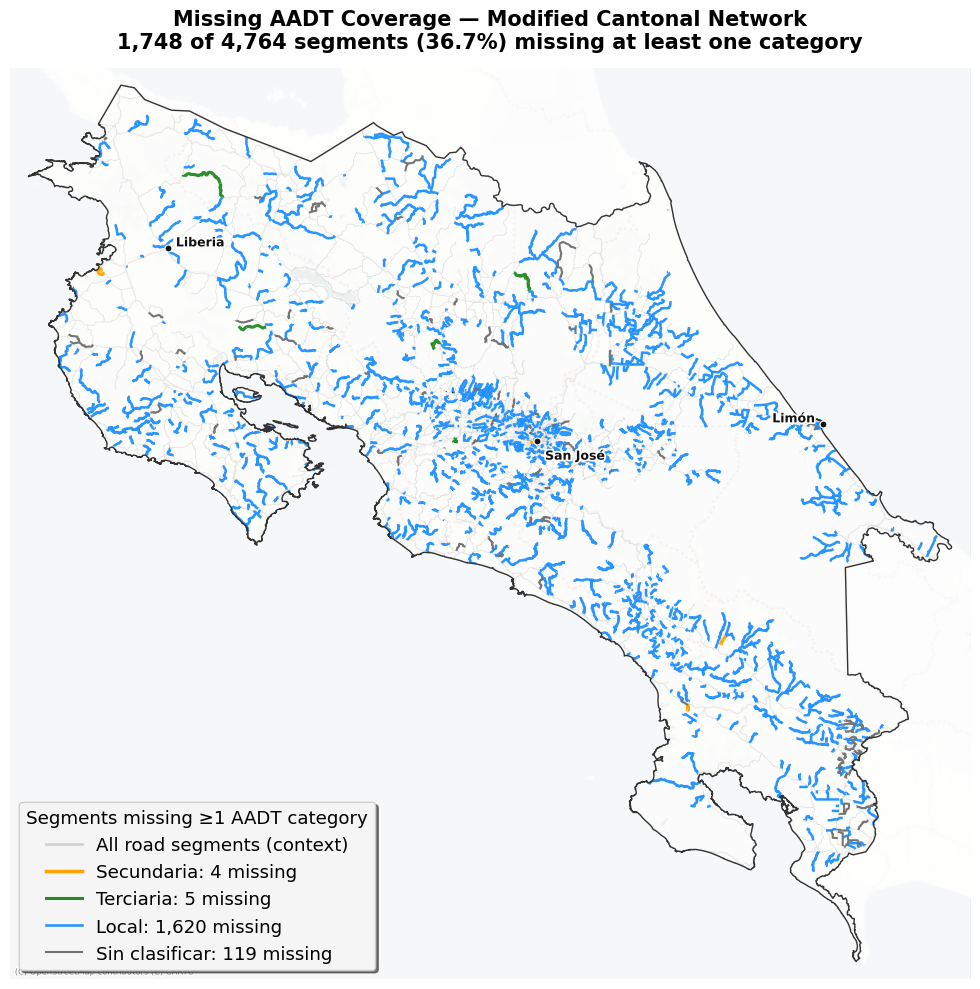

In [ ]:
# Plot road segments with missing AADT values in the modified cantonal network.
# A segment is flagged when at least one of T9-T15 is null; zero is a valid count.
aadt_columns = ['T9', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15']
missing_columns = [column for column in aadt_columns if column not in gdf_modified_cantonal.columns]
if missing_columns:
    raise KeyError(f'Missing expected AADT columns: {missing_columns}')

aadt_coverage = gdf_modified_cantonal.copy()
aadt_coverage['CLASE'] = aadt_coverage['CLASE'].fillna('Sin clasificar')
aadt_coverage['missing_aadt_count'] = aadt_coverage[aadt_columns].isna().sum(axis=1)
missing_aadt_mask = aadt_coverage['missing_aadt_count'].gt(0)
missing_aadt = aadt_coverage.loc[missing_aadt_mask].copy()

n_total = len(aadt_coverage)
n_missing = int(missing_aadt_mask.sum())
missing_pct = 100 * n_missing / n_total if n_total else np.nan
print(f'Segments missing at least one AADT category: {n_missing:,} of {n_total:,} ({missing_pct:.1f}%)')
print('Missing segments by road class:')
display(missing_aadt['CLASE'].value_counts(dropna=False).rename('segments').to_frame())

road_categories = ['Primaria', 'Secundaria', 'Terciaria', 'Local', 'Sin clasificar']
road_colors = {
    'Primaria': '#8B0000', 'Secundaria': '#FFA500', 'Terciaria': '#228B22',
    'Local': '#1E90FF', 'Sin clasificar': '#6F6F6F',
}
road_widths = {
    'Primaria': 3.0, 'Secundaria': 2.5, 'Terciaria': 2.2,
    'Local': 1.8, 'Sin clasificar': 1.5,
}

# Web Mercator is required by the contextily basemap.
coverage_mercator = aadt_coverage.to_crs(3857)
missing_mercator = missing_aadt.to_crs(3857)

fig, ax = plt.subplots(1, 1, figsize=(12, 10), facecolor='white')

# Draw the entire network as subdued context.
coverage_mercator.plot(
    ax=ax, color='#D3D3D3', linewidth=0.55, alpha=0.65, zorder=1
)

# Overlay missing-data segments by road class.
for category in road_categories:
    category_roads = missing_mercator.loc[missing_mercator['CLASE'].eq(category)]
    if not category_roads.empty:
        category_roads.plot(
            ax=ax, color=road_colors[category], linewidth=road_widths[category],
            alpha=0.95, zorder=3,
        )

legend_elements = [
    Line2D([0], [0], color='#D3D3D3', linewidth=2, label='All road segments (context)')
]
for category in road_categories:
    count = int(missing_aadt['CLASE'].eq(category).sum())
    if count:
        legend_elements.append(
            Line2D(
                [0], [0], color=road_colors[category], linewidth=road_widths[category],
                label=f'{category}: {count:,} missing',
            )
        )

style_cr_map(ax, 3857, legend_handles=legend_elements,
             legend_title='Segments missing ≥1 AADT category')
ax.set_title(
    f'Missing AADT Coverage — Modified Cantonal Network\n'
    f'{n_missing:,} of {n_total:,} segments ({missing_pct:.1f}%) missing at least one category',
    fontsize=15, fontweight='bold', pad=14,
)

plt.tight_layout()
plt.savefig(figure_path / 'missing_aadt_modified_cantonal.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
gdf_modified_cantonal.columns

Index(['ID_TRAMO', 'TRAMO_UID', 'ID_RUTA', 'NOMBRE', 'ADMIN', 'CLASE',
       'LONGITUD', 'ANCHO', 'SUPERFICIE', 'REDUNDANCI', 'DIRECCION',
       'CARRILES', 'T9', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15', 'vul_f',
       'vul_eq', 'rep_cost_k', 'VEL_KMH', 'NODO_INI', 'NODO_FIN', 'COD_CAMI_1',
       'Cod_camino', 'geometry'],
      dtype='object')

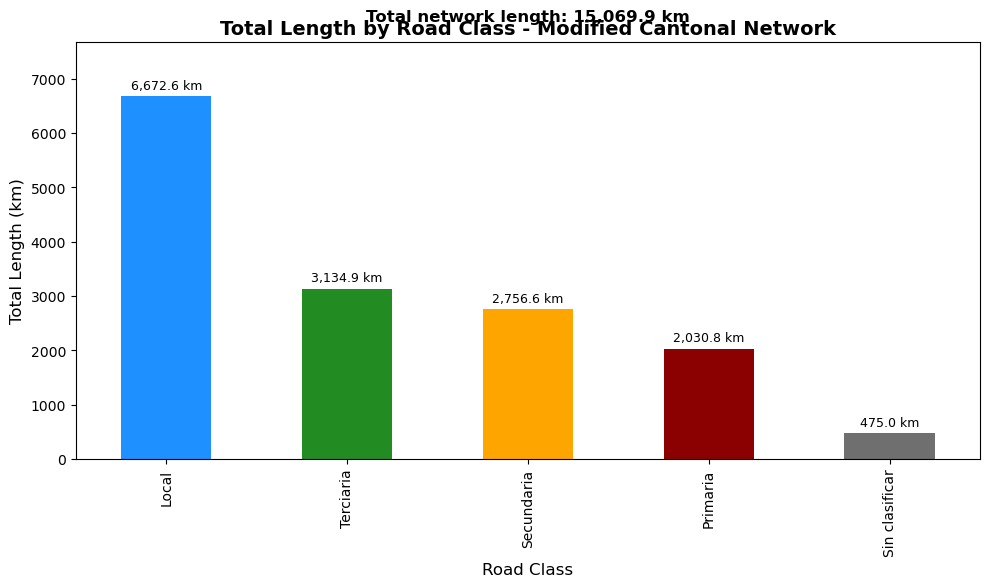

In [ ]:
gdf_modified_cantonal_crtm05 = gdf_modified_cantonal.to_crs(8908)

length_by_class = (
    gdf_modified_cantonal_crtm05
    .assign(length_km=lambda df: df.geometry.length / 1000)
    .groupby("CLASE", as_index=False)["length_km"]
    .sum()
    .sort_values("length_km", ascending=False)
)

total_length_km = length_by_class["length_km"].sum()

ax = length_by_class.plot(
    kind="bar",
    x="CLASE",
    y="length_km",
    color=[road_colors.get(c, "#999999") for c in length_by_class["CLASE"]],
    legend=False,
    figsize=(10, 6)
)

plt.title(
    "Total Length by Road Class - Modified Cantonal Network",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Road Class", fontsize=12, rotation=0)
plt.ylabel("Total Length (km)", fontsize=12)

# Add labels on top of each bar
ax.bar_label(
    ax.containers[0],
    labels=[f"{v:,.1f} km" for v in length_by_class["length_km"]],
    padding=3,
    fontsize=9
)

# Add total length above the plot
ax.text(
    0.5,
    1.05,
    f"Total network length: {total_length_km:,.1f} km",
    transform=ax.transAxes,
    ha="center",
    fontsize=12,
    fontweight="bold"
)

# Give labels some room
ax.set_ylim(0, length_by_class["length_km"].max() * 1.15)

plt.tight_layout()
plt.show()